In [19]:
import numpy as np
import cv2 as cv2
import matplotlib.pyplot as plt

In [20]:
img = cv2.imread("anhTest.jpg", cv2.IMREAD_GRAYSCALE)

## Một số hàm dùng hỗ trợ

In [21]:
def display(title, img):
    cv2.imshow(title, img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [22]:
def DrawHistogram(img):
    hist, bin_edges = np.histogram(img.flatten(), bins=256, range=[0, 256])

    plt.figure(figsize=(10, 4))
    plt.title("Biểu đồ Histogram")
    plt.xlabel("Mức xám (Intensity)")
    plt.ylabel("Số lượng pixel: ")

    # Dùng bin_edges[:-1] làm tọa độ x, chiều rộng cột là 1
    plt.bar(bin_edges[:-1], hist, width=1.0)

    plt.xlim([0, 256])
    plt.show()

## Xây dựng bảng tra duy nhất cho toàn ảnh

In [23]:
N = img.shape[0] * img.shape[1]
hist, bins = np.histogram(img)

L = 256
c = np.zeros(len(hist))
T = np.zeros(len(hist))

for k in range(0, len(hist)):
    c[k] = (1/N) * np.cumsum(hist)[k]

for k2 in range(0, len(c)):
    T[k2] = np.round((L - 1)*c[k2])

print("Bảng tra T có giá trị như sau")
print(T)

Bảng tra T có giá trị như sau
[224. 241. 248. 250. 252. 253. 253. 254. 254. 255.]


In [24]:
# Tính toán CDF (Đạo hàm của bảng tra)
CDF =  np.zeros(len(hist))

for k in range(0, len(hist)):
    CDF[k] = (L - 1) * (hist[k] / N)

print(CDF)
print("Ta nhận thấy có độc dốc rất lớn")

[224.315       16.55233333   6.9955       2.50466667   1.462
   0.92366667   0.62333333   0.51         0.35416667   0.75933333]
Ta nhận thấy có độc dốc rất lớn


## Xây dựng hàm

In [25]:

def clip_histogram(hist, clip_limit):
    """Cắt và phân phối lại lược đồ.
    hist: mảng (L,) số nguyên. Trả về mảng (L,) đã cắt, tổng không đổi."""

    # Khởi tạo một số biến cần thiết
    Alpha = 120
    e_k = np.zeros(len(hist))

    # Tính toán chỉ số B (đoạn cần cắt)
    B = (N/L) * (1 + (Alpha/100) * (clip_limit - 1))

   # Tính toán e
    for k in range(0, len(e_k)):
        if (hist[k] > B):
            e_k[k] = hist[k] - B
            hist[k] = B

    # Cộng tổng phần dư
    E = np.sum(e_k)

    # Phân phối E đều lại cho toàn bộ L mức h[k] <= h[k] + [E/L]
    for k in range(0, len(hist)):
        hist[k] = hist[k] + E/(len(hist))

    # Phần pixel còn lại
    last = N - np.sum(hist)
    
    hist[0] = hist[0] + last
    return hist

In [26]:
# Test
hist = clip_histogram(hist, 20)
print(hist)
print(np.sum(hist))

[15450 12922  9549  7964  7596  7406  7300  7260  7205  7348]
90000


In [27]:
def _pad_to_grid(img, grid):
    """Padding phản xạ để H, W chia hết cho lưới."""
    gy, gx = grid
    H, W = img.shape
    ph = (-H) % gy
    pw = (-W) % gx
    if ph or pw:
        img = np.pad(img, ((0, ph), (0, pw)), mode="reflect")
    return img

In [28]:
def build_tile_luts(img, grid=(8, 8), clip_limit=2.0):
    """Trả về mảng (Gy, Gx, L) uint8: bảng tra của từng ô."""
    gy, gx = grid
    padded = _pad_to_grid(np.asarray(img, dtype=np.uint8), grid)
    th = padded.shape[0] // gy
    tw = padded.shape[1] // gx
    
    luts = np.zeros((gy, gx, L), dtype=np.uint8)
    for i in range(gy):
        for j in range(gx):
            tile = padded[i * th:(i + 1) * th, j * tw:(j + 1) * tw]
            hist = np.bincount(tile.ravel(), minlength=L)
            hist = clip_histogram(hist, clip_limit)
            cdf = np.cumsum(hist)
            lut = np.rint(cdf * (L - 1) / cdf[-1])
            luts[i, j] = np.clip(lut, 0, L - 1).astype(np.uint8)
    return luts

In [29]:
def clahe(img, grid=(8, 8), clip_limit=2.0):
    """CLAHE đầy đủ. img: (H, W) uint8. Trả về (H, W) uint8."""
    img = np.asarray(img, dtype=np.uint8)
    H, W = img.shape
    gy, gx = grid
    luts = build_tile_luts(img, grid, clip_limit)

    # Kích thước ô (theo ảnh đã padding)
    th = (H + (-H) % gy) // gy
    tw = (W + (-W) % gx) // gx

    # Toạ độ liên tục theo tâm ô: tâm ô i nằm ở (i + 0.5) * th
    fy = (np.arange(H) + 0.5) / th - 0.5
    fx = (np.arange(W) + 0.5) / tw - 0.5

    y0f = np.floor(fy)
    x0f = np.floor(fx)
    wy = (fy - y0f)[:, None]
    wx = (fx - x0f)[None, :]
    y0 = np.clip(y0f, 0, gy - 1).astype(int)[:, None]
    y1 = np.clip(y0f + 1, 0, gy - 1).astype(int)[:, None]
    x0 = np.clip(x0f, 0, gx - 1).astype(int)[None, :]
    x1 = np.clip(x0f + 1, 0, gx - 1).astype(int)[None, :]

    # LUT của 4 ô lân cận, tra theo giá trị pixel
    v00 = luts[y0, x0, img].astype(np.float64)
    v01 = luts[y0, x1, img].astype(np.float64)
    v10 = luts[y1, x0, img].astype(np.float64)
    v11 = luts[y1, x1, img].astype(np.float64)

    top = v00 * (1 - wx) + v01 * wx
    bot = v10 * (1 - wx) + v11 * wx
    out = top * (1 - wy) + bot * wy
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)
    pass

## Test


Độ lệch chuẩn: 26.0 -> 1.0


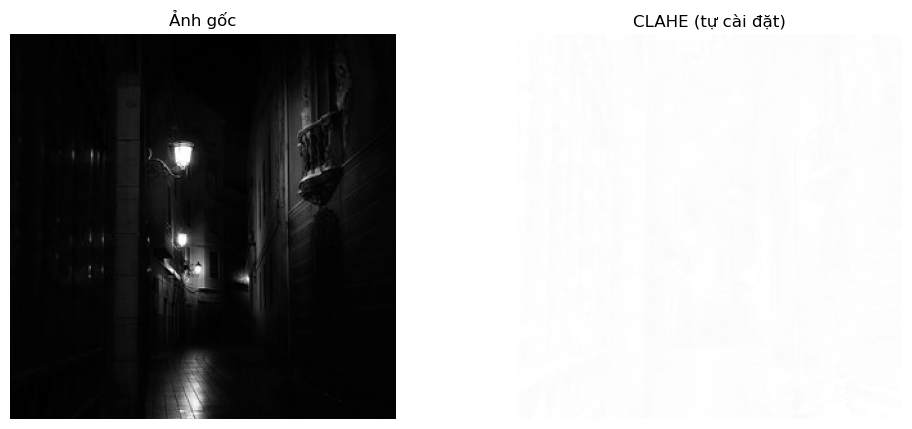

In [30]:
my_img = clahe(img, grid=(8, 8), clip_limit=2.0)

assert my_img.shape == img.shape and my_img.dtype == np.uint8
print("Độ lệch chuẩn:", img.std().round(1), "->", my_img.std().round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Ảnh gốc"); ax[0].axis("off")
ax[1].imshow(my_img, cmap="gray", vmin=0, vmax=255); ax[1].set_title("CLAHE (tự cài đặt)"); ax[1].axis("off")
plt.show()

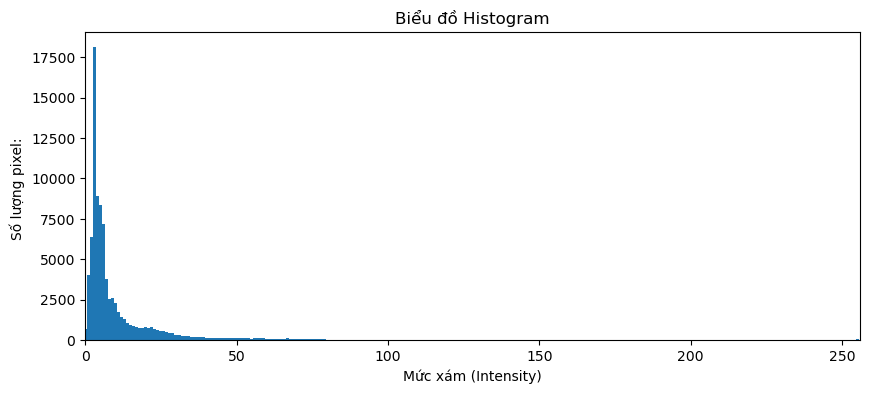

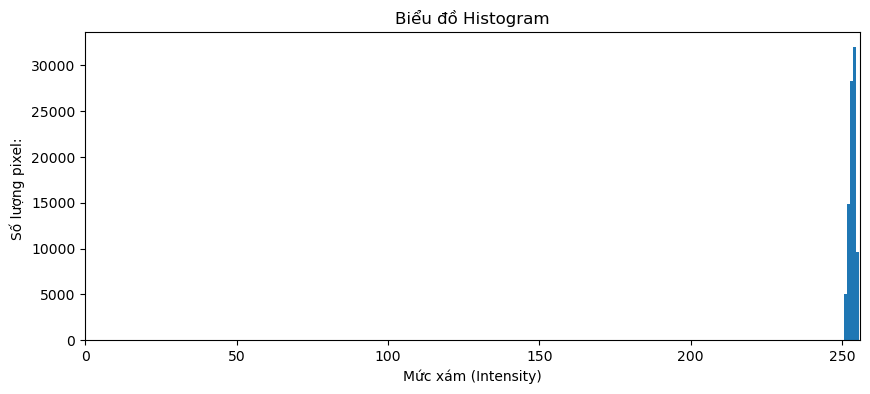

In [31]:
DrawHistogram(img)
DrawHistogram(my_img)

## Đối chiếu

In [32]:
# Đây là ô đối chiếu dùng để kiểm tra kết quả in ra của các hàm trên

clahe = cv2.createCLAHE(clipLimit=5)
clahe_img = np.clip(clahe.apply(img) + 25, 0, 255).astype(np.uint8)

display("CLAHE image", clahe_img)

In [33]:
np.histogram(clahe_img)

(array([  602, 44514, 21831,  7457,  4889,  4122,  2666,  1635,  1338,
          946]),
 array([  0. ,  25.5,  51. ,  76.5, 102. , 127.5, 153. , 178.5, 204. ,
        229.5, 255. ]))

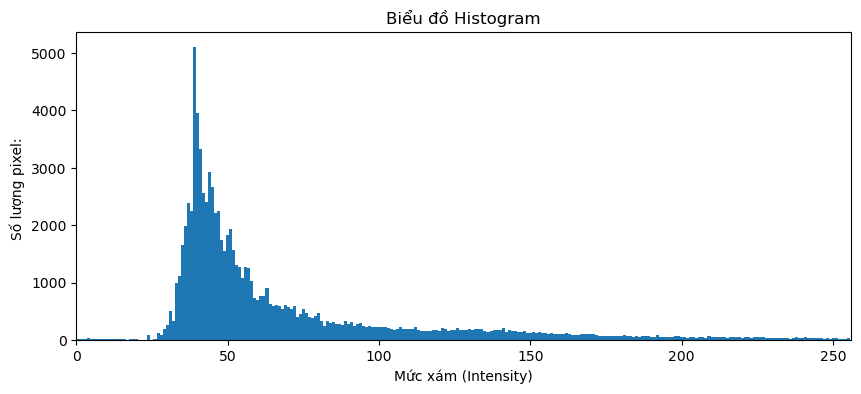

In [34]:
DrawHistogram(clahe_img)

### Đối chiếu công bằng với OpenCV

Để so sánh đúng, ta đặt `ALPHA = 100` (khi đó $B = \text{clip\_limit}\cdot N/L$, giống OpenCV), dùng cùng `clipLimit` và cùng lưới, không cộng thêm `+25`.
Hai kết quả sẽ rất gần nhau nhưng không trùng từng pixel, vì OpenCV nội suy bằng số nguyên cố định và phân phối phần dư theo cách hơi khác.

In [35]:
ALPHA = 100
mine = clahe(img, grid=(8, 8), clip_limit=2.0)
ref = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)
ALPHA = 120   # trả về giá trị ban đầu

diff = np.abs(mine.astype(int) - ref.astype(int))
print("Sai khác trung bình mỗi pixel:", diff.mean().round(2))
print("Sai khác lớn nhất:", diff.max())
print("Tỉ lệ pixel lệch quá 5 mức xám:", (diff > 5).mean().round(4))

TypeError: 'cv2.CLAHE' object is not callable